# 01 — Can recorded sales support inventory planning?

Project 03 · Demand and Inventory Planner · Initial milestone, 2026-10-21

This notebook examines the committed UCI Online Retail II observations and the reproducible audit outputs. It does **not** fit a model or estimate business savings. The full history is visible for descriptive quality checks; final-test forecasting remains unrun. Read the [charter](../docs/project-charter.md), [evaluation plan](../docs/evaluation-plan.md), and [audit](../docs/reports/01-data-audit.md).

Run `python scripts/audit.py` from the project root first. Then run all cells, using the repository's pinned requirements.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Run from project root or notebooks/'
assert (ROOT / 'data/processed/weekly-sales.csv').exists(), 'Run python scripts/audit.py first'
config = json.loads((ROOT / 'config.json').read_text())
audit = json.loads((ROOT / 'docs/reports/data-audit.json').read_text())
panel = pd.read_csv(ROOT / 'data/processed/weekly-sales.csv', dtype={'StockCode': str}, parse_dates=['week'])
products = pd.read_csv(ROOT / 'data/processed/selected-products.csv', dtype={'StockCode': str})
origins = pd.read_csv(ROOT / 'data/processed/forecast-origins.csv', parse_dates=['origin', 'history_through', 'target_end'])
sales = pd.read_csv(ROOT / 'data/interim/uk-sales.csv', usecols=['StockCode', 'week', 'Quantity'], dtype={'StockCode': str}, parse_dates=['week'])
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})

## 0. Start with the actual transaction rows

Each row is one recorded invoice line for a product or accounting entry. An invoice can contain many lines; one row is not one customer, one invoice or one week. These are the original committed CSV values, before filtering, overlap reconciliation or weekly aggregation.

| Source field | Meaning in this notebook |
|---|---|
| `Invoice` | Invoice reference; cancellation references can begin with C |
| `StockCode` | Product or accounting-entry code |
| `Description` | Recorded item description; sometimes missing |
| `Quantity` | Recorded units on the line; can be negative |
| `InvoiceDate` | Transaction date and time |
| `Price` | Recorded unit price; not the retailer's procurement cost |
| `Customer ID` | Customer reference; sometimes missing |
| `Country` | Recorded customer country; not a warehouse identifier |

We reuse the audit loader to verify checksums and preserve identifiers as strings. It adds provenance columns separately from the eight source columns. Loading all exports also lets us inspect exceptional records beyond the first file.

In [2]:
import importlib.util
spec = importlib.util.spec_from_file_location('retail_audit', ROOT / 'scripts/audit.py')
audit_tools = importlib.util.module_from_spec(spec)
spec.loader.exec_module(audit_tools)
raw, source_manifest = audit_tools.load_source(ROOT)
print(f'{len(raw):,} original invoice lines across {len(source_manifest["files"])} CSV exports')
print(f'First ten unchanged source rows: {raw.source_file.iloc[0]} (zero-based data rows 0–9, excluding the header)')
display(raw[audit_tools.COLUMNS].head(10))
display(pd.DataFrame({'loaded_dtype': raw[audit_tools.COLUMNS].dtypes.astype(str),
                      'missing_rows': raw[audit_tools.COLUMNS].isna().sum()}))
assert len(raw) == audit['raw_rows']

1,067,371 original invoice lines across 12 CSV exports
First ten unchanged source rows: retail_sheet1_001.csv (zero-based data rows 0–9, excluding the header)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085,United Kingdom


,loaded_dtype,missing_rows
Invoice,string,0
StockCode,string,0
Description,string,4382
Quantity,int64,0
InvoiceDate,string,0
Price,float64,0
Customer ID,string,243007
Country,string,0


### Raw examples that explain the cleaning rules

The first ten rows alone cannot reveal every issue. Below are original source examples of cancellations, nonpositive prices, missing customer IDs and non-product codes. The examples are selected to illustrate those conditions, not to represent their frequency. A cancellation is excluded from positive sales; a missing customer ID alone does **not** exclude a line. Source invoice/date text and all other displayed values remain unchanged.

In [3]:
raw_examples = {
    'Cancellation / return invoice': raw.Invoice.str.upper().str.startswith('C'),
    'Zero or negative recorded price': raw.Price.le(0),
    'Missing customer ID': raw['Customer ID'].isna(),
    'Code outside the product-code scope': ~raw.StockCode.str.fullmatch(config['product_code_pattern']),
}
for label, mask in raw_examples.items():
    print(f'{label}: {int(mask.sum()):,} raw rows; first two examples')
    display(raw.loc[mask, audit_tools.COLUMNS].head(2))

Cancellation / return invoice: 19,494 raw rows; first two examples


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia


Zero or negative recorded price: 6,207 raw rows; first two examples


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom


Missing customer ID: 243,007 raw rows; first two examples


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom


Code outside the product-code scope: 6,094 raw rows; first two examples


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.0,12682,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.0,12636,USA


### Follow one product from invoice lines to a forecast target

Use the leading product by **training-period** units as a concrete example. The transformation is:

1. On dates shared by workbook sheets, retain the later sheet's lines. This resolves source overlap while retaining repeated lines within that sheet.
2. Keep UK positive-quantity, positive-price, noncancellation lines with an eligible product-code pattern. Keep missing customer IDs.
3. Keep complete Monday–Sunday calendar weeks and assign each retained line to its Monday.
4. For each product and week, sum `Quantity`. This sum is the weekly sales target. Fill later weeks without retained sales with zero, starting only at the product's first observed complete-week sale.

The displays below show retained invoice lines and the explicit arithmetic for one training week, then compare the first eight weekly totals with the saved forecasting panel. Recorded zeros cannot establish that the product was in stock.

In [4]:
reconciled, overlap_removed = audit_tools.reconcile_sheets(raw)
first_complete, last_complete = audit_tools.complete_bounds(reconciled)
kept = reconciled.loc[audit_tools.sales_mask(reconciled, config)].copy()
kept['week'] = kept.timestamp.dt.to_period('W-SUN').dt.start_time
kept = kept.loc[kept.week.ge(first_complete) & kept.week.le(last_complete - pd.Timedelta(days=6))]
assert len(kept) == audit['filtered_sales_rows_complete_weeks']

example_sku = str(products.StockCode.iloc[0])
product_lines = kept.loc[kept.StockCode.eq(example_sku)].sort_values(['timestamp', 'source_file', 'source_row'])
example_week = product_lines.week.min()
week_lines = product_lines.loc[product_lines.week.eq(example_week)]
print(f'Product {example_sku}: original values on retained lines for the week starting {example_week.date()}')
display(week_lines[audit_tools.COLUMNS].head(10))
if len(week_lines) > 10:
    print(f'Showing 10 of {len(week_lines)} lines; the calculation below includes every line in that week.')
print(f'Quantity sum: {" + ".join(week_lines.Quantity.astype(str))} = {week_lines.Quantity.sum():,} units')

line_totals = product_lines.groupby('week').agg(invoice_lines=('Quantity', 'size'),
                                                       invoice_references=('Invoice', 'nunique'),
                                                       sum_of_line_quantities=('Quantity', 'sum'))
saved_product = panel.loc[panel.StockCode.eq(example_sku), ['week', 'units', 'split']].set_index('week')
trace = saved_product.join(line_totals)
for column in ['invoice_lines', 'invoice_references', 'sum_of_line_quantities']:
    trace[column] = trace[column].fillna(0).astype(int)
assert np.array_equal(trace.units.to_numpy(), trace.sum_of_line_quantities.to_numpy())
assert trace.loc[example_week, 'units'] == week_lines.Quantity.sum()
print('Each row below is now one product-week, rather than one invoice line:')
display(trace.head(8).rename(columns={'units': 'forecast_target_units'}))
print('PASS: recalculated line quantities match every saved weekly target for this product.')
# Release the full transaction frames after the walkthrough; later sections use compact audit outputs.
del raw, reconciled, overlap_removed, kept, product_lines, week_lines


Product 84077: original values on retained lines for the week starting 2009-12-07


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
15174,490675,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2009-12-07 13:07:00,0.21,14695,United Kingdom
15395,490685,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2009-12-07 13:48:00,0.21,13206,United Kingdom
17826,490847,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,144,2009-12-08 12:46:00,0.21,15093,United Kingdom
18172,490933,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,288,2009-12-08 13:46:00,0.18,14063,United Kingdom
19331,490978,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2009-12-08 16:43:00,0.21,17329,United Kingdom
19406,490989,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,96,2009-12-08 17:08:00,0.21,15674,United Kingdom
22860,491170,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2009-12-10 11:27:00,0.21,17861,United Kingdom
23322,491193,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,96,2009-12-10 12:44:00,0.21,13091,United Kingdom
23374,491197,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2009-12-10 13:03:00,0.21,15912,United Kingdom
23974,491356,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,96,2009-12-10 15:52:00,0.21,15738,United Kingdom


Showing 10 of 15 lines; the calculation below includes every line in that week.
Quantity sum: 48 + 48 + 144 + 288 + 48 + 96 + 48 + 96 + 48 + 96 + 96 + 48 + 48 + 4 + 48 = 1,204 units
Each row below is now one product-week, rather than one invoice line:


,forecast_target_units,split,invoice_lines,invoice_references,sum_of_line_quantities
week,,,,,
2009-12-07,1204,train,15,15,1204
2009-12-14,720,train,9,9,720
2009-12-21,48,train,1,1,48
2009-12-28,0,train,0,0,0
2010-01-04,336,train,5,5,336
2010-01-11,384,train,3,3,384
2010-01-18,195,train,4,4,195
2010-01-25,432,train,4,4,432


PASS: recalculated line quantities match every saved weekly target for this product.


## 1. What did the workbook overlap change?

The sheets cover overlapping December 2010 dates. Calendar-date ownership goes to the later sheet; matching rows in the earlier sheet are not additional sales. Repeated rows within the retained sheet remain because the source has no reliable line-item key. This differs from indiscriminately dropping every identical row.

In [5]:
display(pd.Series({k: audit[k] for k in ['raw_rows', 'reconciled_rows', 'filtered_sales_rows_complete_weeks', 'selected_products', 'panel_rows', 'selected_training_unit_share']}, name='audited value').to_frame())
display(pd.DataFrame(audit['sheets']).T)
display(pd.Series(audit['overlap'], name='overlap evidence').to_frame())
print(f"Retained exact repeats: {audit['retained_exact_repeats_beyond_first']:,}")
print(f"Dropping within-sheet repeats removes {audit['sales_repeat_units_sensitivity']:,} eligible units (sensitivity only).")
assert audit['overlap']['removed_rows_with_exact_later_sheet_match'] == audit['overlap']['removed_earlier_sheet_rows']

,audited value
raw_rows,1.067371e+06
reconciled_rows,1.044848e+06
filtered_sales_rows_complete_weeks,9.051620e+05
selected_products,5.000000e+01
panel_rows,5.097000e+03
selected_training_unit_share,2.192629e-01


,rows,start,end,exact_repeats_beyond_first
1,525461,2009-12-01 07:45:00,2010-12-09 20:01:00,6865
2,541910,2010-12-01 08:26:00,2011-12-09 12:50:00,5268


,overlap evidence
removed_earlier_sheet_rows,22523
dates,"[2010-12-01, 2010-12-02, 2010-12-03, 2010-12-0..."
removed_rows_with_exact_later_sheet_match,22523


Retained exact repeats: 11,812
Dropping within-sheet repeats removes 32,224 eligible units (sensitivity only).


## 2. Which fields and records need caution?

Customer identifiers are missing for many rows, but weekly SKU sales do not require them. Returns, nonpositive quantities/prices, postage and adjustments must not become product demand. These flags overlap. The product-code pattern is a scope heuristic; excluded codes require review before a broader catalog release.

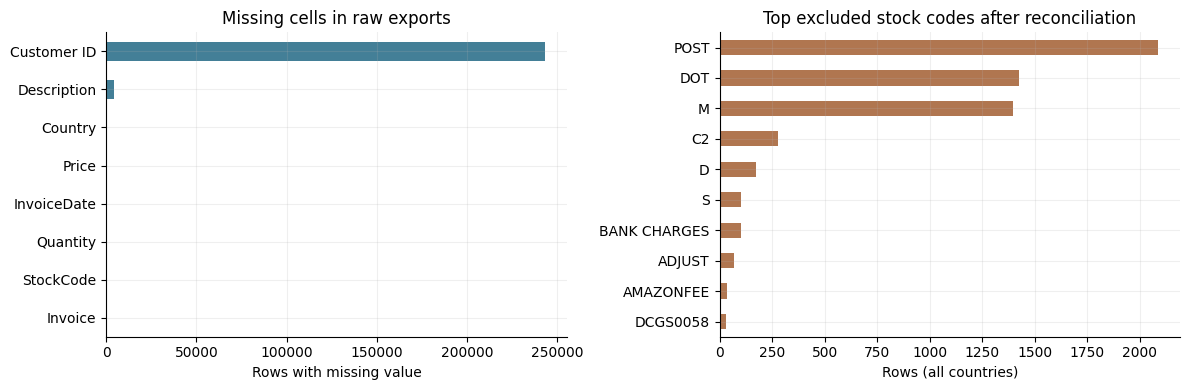

,rows; overlapping flags
reconciled_cancellations,19165
reconciled_nonpositive_quantity,22557
reconciled_nonpositive_price,6029
sales_missing_customer_id,214722


In [6]:
missing = pd.Series(audit['missing_by_column']).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
missing.plot.barh(ax=axes[0], color='#437f97', title='Missing cells in raw exports')
axes[0].set_xlabel('Rows with missing value')
pd.Series(audit['excluded_code_rows']).head(10).sort_values().plot.barh(ax=axes[1], color='#b07650', title='Top excluded stock codes after reconciliation')
axes[1].set_xlabel('Rows (all countries)')
fig.tight_layout()
plt.show()
display(pd.Series({k: audit[k] for k in ['reconciled_cancellations', 'reconciled_nonpositive_quantity', 'reconciled_nonpositive_price', 'sales_missing_customer_id']}, name='rows; overlapping flags').to_frame())

## 3. Is the first application population supported?

Start with the UK because it dominates the observed records. Country is not evidence of a separate warehouse or inventory pool. Product eligibility and volume ranking use only weeks before 2011-06-06; test-period popularity cannot select products. This initial universe is established high-volume products, not the whole catalog.

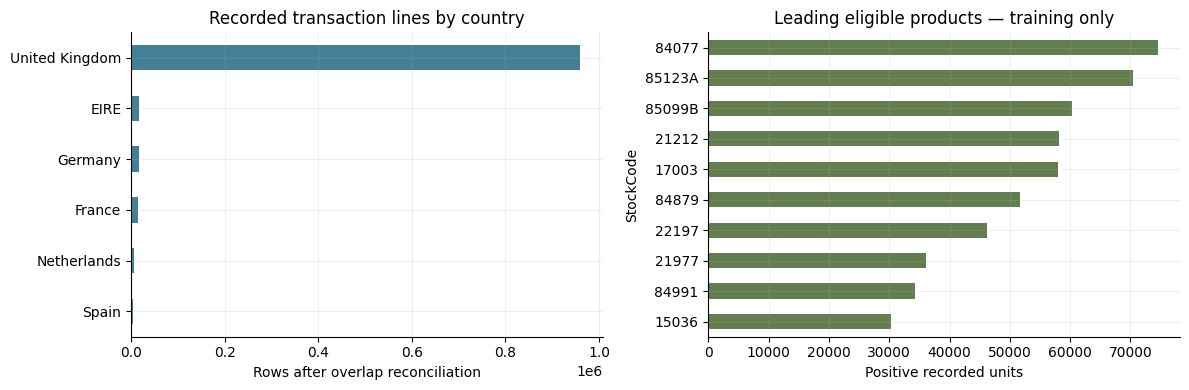

Selected products account for 21.9% of eligible UK training units.


,StockCode,first_training_week,active_training_weeks,training_units,history_weeks
0,84077,2009-12-07,75,74510,78
1,85123A,2009-12-07,76,70501,78
2,85099B,2009-12-07,76,60340,78
3,21212,2009-12-07,76,58149,78
4,17003,2009-12-07,70,58039,78
5,84879,2009-12-07,76,51682,78
6,22197,2009-12-07,76,46291,78
7,21977,2009-12-07,76,36152,78
8,84991,2009-12-07,76,34235,78
9,15036,2009-12-07,74,30280,78


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(audit['countries']).head(6).sort_values().plot.barh(ax=axes[0], color='#437f97', title='Recorded transaction lines by country')
axes[0].set_xlabel('Rows after overlap reconciliation')
products.head(10).set_index('StockCode').training_units.sort_values().plot.barh(ax=axes[1], color='#627e4e', title='Leading eligible products — training only')
axes[1].set_xlabel('Positive recorded units')
fig.tight_layout()
plt.show()
print(f"Selected products account for {audit['selected_training_unit_share']:.1%} of eligible UK training units.")
display(products.head(10))

## 4. How does recorded sales volume change over time?

Aggregate the retained positive-sales lines into complete Monday–Sunday weeks. The selected series share calendar shocks. High peaks may be real bulk orders or anomalies; keep them visible and investigate rather than removing them after seeing their impact on a model. The last partial week is excluded.

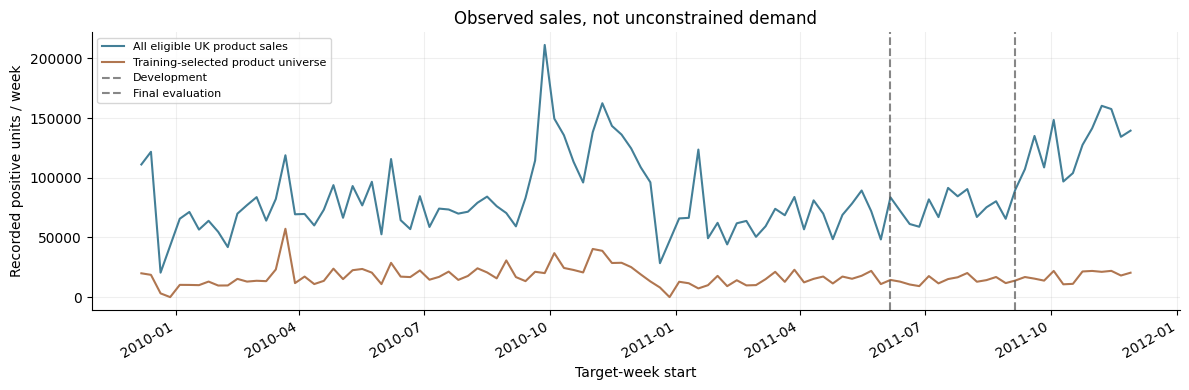

In [8]:
all_weekly = sales.groupby('week').Quantity.sum()
selected_weekly = panel.groupby('week').units.sum()
fig, ax = plt.subplots(figsize=(12, 4))
all_weekly.plot(ax=ax, label='All eligible UK product sales', color='#437f97')
selected_weekly.plot(ax=ax, label='Training-selected product universe', color='#b07650')
for key, label in [('development_start', 'Development'), ('test_start', 'Final evaluation')]:
    ax.axvline(pd.Timestamp(config[key]), color='#555555', linestyle='--', alpha=.7, label=label)
ax.set(ylabel='Recorded positive units / week', xlabel='Target-week start', title='Observed sales, not unconstrained demand')
ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()
plt.show()

## 5. Are the chosen products smooth, intermittent or extreme?

Zero-fill only after a product's first observed complete-week sale. Earlier periods are absent, not assumed zeros. A zero can reflect no demand, stockout, closure or delisting; the source does not distinguish these explanations. Per-series plots and zero fractions expose failures hidden by aggregate volume.

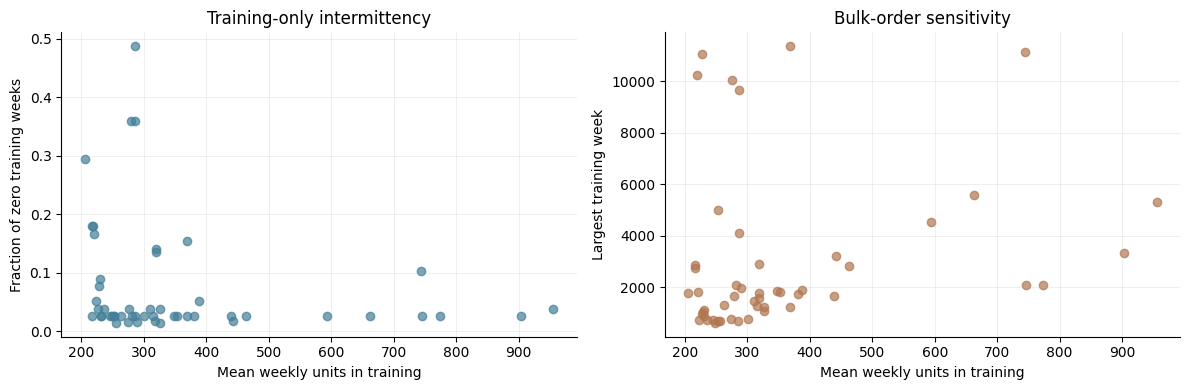

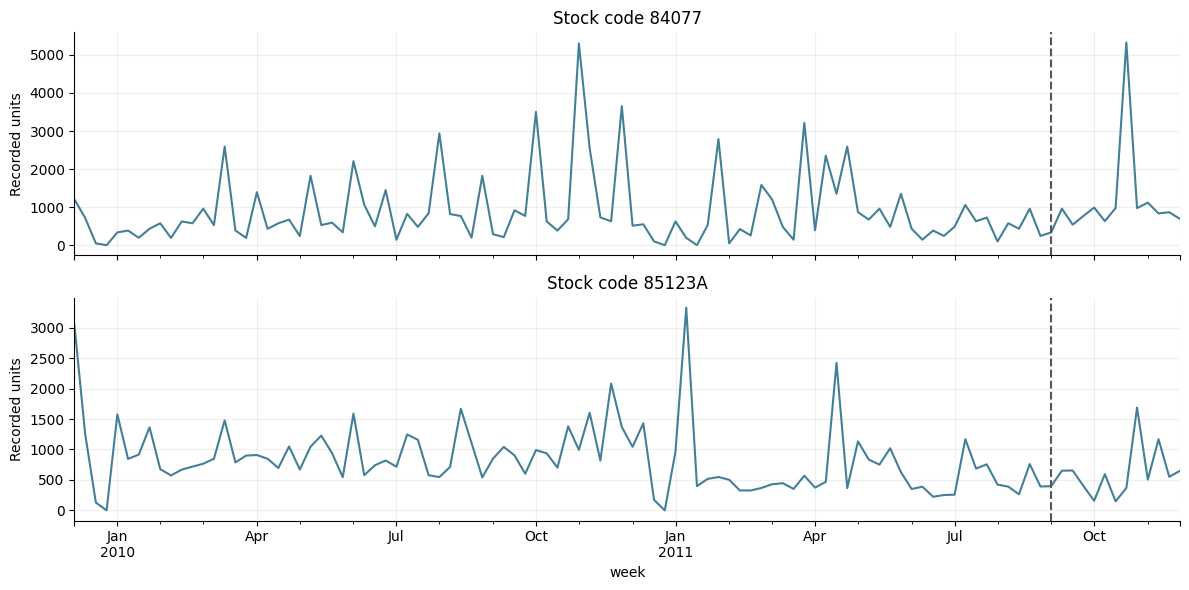

,mean,max,count,zero_fraction
StockCode,,,,
21982,368.730769,11366,78,0.153846
17003,744.089744,11138,78,0.102564
21984,228.115385,11061,78,0.076923
21981,218.756410,10264,78,0.179487
21980,275.410256,10070,78,0.038462
84347,285.910256,9679,78,0.358974
84879,662.589744,5584,78,0.025641
84077,955.256410,5301,78,0.038462
21985,252.897436,5007,78,0.025641


In [9]:
train = panel.loc[panel.split.eq('train')]
profile = train.groupby('StockCode').units.agg(['mean', 'max', 'count'])
profile['zero_fraction'] = train.groupby('StockCode').units.apply(lambda x: x.eq(0).mean())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(profile['mean'], profile.zero_fraction, color='#437f97', alpha=.7)
axes[0].set(xlabel='Mean weekly units in training', ylabel='Fraction of zero training weeks', title='Training-only intermittency')
axes[1].scatter(profile['mean'], profile['max'], color='#b07650', alpha=.7)
axes[1].set(xlabel='Mean weekly units in training', ylabel='Largest training week', title='Bulk-order sensitivity')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, sku in zip(axes, products.StockCode.head(2)):
    series = panel.loc[panel.StockCode.eq(sku)].set_index('week').units
    series.plot(ax=ax, color='#437f97', label=sku)
    ax.axvline(pd.Timestamp(config['test_start']), color='#555555', linestyle='--')
    ax.set(ylabel='Recorded units', title=f'Stock code {sku}')
fig.tight_layout()
plt.show()
display(profile.sort_values('max', ascending=False).head(10))

## 6. Can we evaluate without temporal leakage?

Each Monday origin predicts the next four weekly sales totals. All features must be available by the preceding Sunday, including at horizons 2–4; actual target-week sales may never feed a lag feature. All target weeks of one origin stay in the same development or final partition. Products remain fixed by initial training history.

The final exercise will use a frozen walk-forward recipe: earlier completed final-period outcomes can enter later fits once observed. Overlapping windows and common calendar shocks limit independent evidence. Compare paired forecasts at the same origins and bootstrap blocks of origins, carrying products together.

,product_weeks,products,first_week,last_week
split,,,,
development,650,50,2011-06-06,2011-08-29
test,650,50,2011-09-05,2011-11-28
train,3797,50,2009-12-07,2011-05-30


,origins,first_origin,last_origin,last_target_end
split,,,,
development,10,2011-06-06,2011-08-08,2011-09-04
test,10,2011-09-05,2011-11-07,2011-12-04


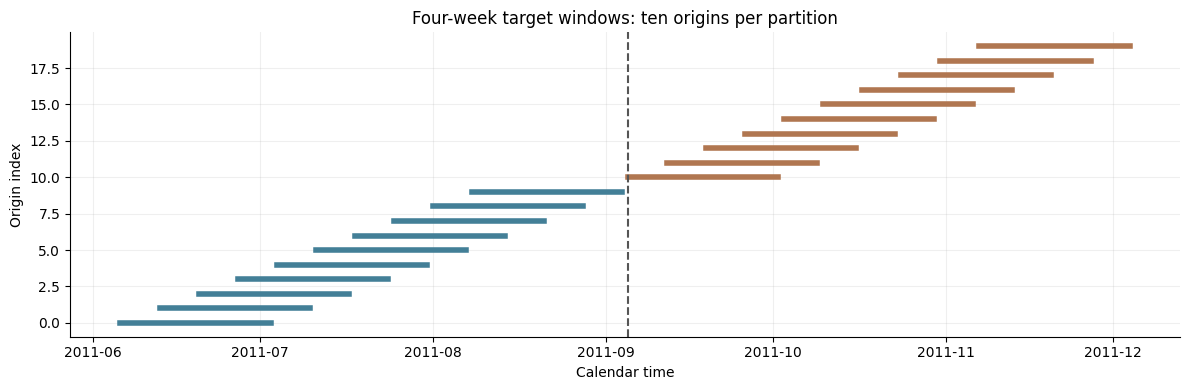

In [10]:
display(panel.groupby('split').agg(product_weeks=('units', 'size'), products=('StockCode', 'nunique'), first_week=('week', 'min'), last_week=('week', 'max')))
display(origins.groupby('split').agg(origins=('origin', 'size'), first_origin=('origin', 'min'), last_origin=('origin', 'max'), last_target_end=('target_end', 'max')))
assert not panel.duplicated(['StockCode', 'week']).any()
assert panel.units.ge(0).all()
assert (origins.history_through < origins.origin).all()
assert (origins.loc[origins.split.eq('development'), 'target_end'] < pd.Timestamp(config['test_start'])).all()
fig, ax = plt.subplots(figsize=(12, 4))
for i, row in enumerate(origins.itertuples()):
    ax.plot([row.origin, row.target_end], [i, i], linewidth=4, color='#437f97' if row.split == 'development' else '#b07650')
ax.axvline(pd.Timestamp(config['test_start']), color='#555555', linestyle='--')
ax.set(title='Four-week target windows: ten origins per partition', xlabel='Calendar time', ylabel='Origin index')
fig.tight_layout()
plt.show()

## What this notebook establishes

The raw invoice-line examples and worked product-week calculation connect the source data to the **recorded-sales forecasting target**. The audit supports the fixed UK product universe, subject to overlap handling, returns, repeated lines, uncertain availability and extreme orders.

Continue to [02 — Forecasting methods](02-forecasting-methods.ipynb) for the implemented development comparisons of simple baselines, Prophet and pooled lag-feature models. Cumulative uncertainty calibration, inventory-policy evaluation, final forecasting evaluation, deployment and the full MLOps lifecycle remain outstanding.

Purchase costs, replenishment actions, lead times, on-hand stock and lost sales are unavailable. The planned inventory application must label these as scenario inputs; no real service-level or savings claim follows from this audit.